# Demo XGBoost: feature → validation → dự báo

Chạy XGBoost qua các cell quan sát được. Thuật toán và quy tắc chọn dùng lại source/config; không dùng dữ liệu test cho scaler hoặc chọn siêu tham số.

Chạy từ trên xuống bằng **Restart Kernel → Run All**, hoặc Shift+Enter từng cell. Thuật toán dùng lại từ `source/`; không sửa các CSV nghiên cứu đã có. Xem `notebooks/README.md` để cấu hình đường dẫn/kernel.

## Đường dẫn và môi trường
Kiểm tra các đường dẫn trước khi chạy. Các notebook độc lập: mặc định đọc clean/preparation đã lưu; không yêu cầu chạy notebook trước để có biến trong RAM.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (p/'source/preprocessing').is_dir() and (p/'notebooks').is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Open this notebook from the repository root or notebooks directory.')
for folder in [PROJECT_ROOT, PROJECT_ROOT/'notebooks', PROJECT_ROOT/'source/preprocessing']:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from demo_support import (configure, show_paths, demo_directory, save_table, save_json,
                          show_source, show_png, environment, compare_values, read_series, series_plot)
PATHS = configure(PROJECT_ROOT)
# Nếu cần, sửa PATHS.population_raw / history_raw / population_clean / history_clean / preparation tại đây.
show_paths(PATHS)
print('Python kernel:', sys.executable)


,setting,path,exists
0,project,D:\Phân tích kinh doanh_2627\GitHub\IS403.R14....,True
1,data_root,D:\Phân tích kinh doanh_2627,True
2,population_raw,D:\Phân tích kinh doanh_2627\archive\Electric_...,True
3,history_raw,D:\Phân tích kinh doanh_2627\Electric_Vehicle_...,True
4,population_clean,D:\Phân tích kinh doanh_2627\archive\EV_Popula...,True
5,history_clean,D:\Phân tích kinh doanh_2627\Electric_Vehicle_...,True
6,preparation,D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\...,True
7,output_root,D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\...,True


Python kernel: c:\Users\ASUS\AppData\Local\Programs\Python\Python312\python.exe


In [2]:
OUT = demo_directory(PATHS, 'xgboost')
print('Output demo:', OUT)
display(environment())


Output demo: D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\notebook_demo\xgboost_20261116_041004_16b545ce


,package,version,status
0,pandas,3.0.5,Đã tìm thấy
1,numpy,2.5.3,Đã tìm thấy
2,scipy,1.18.1,Đã tìm thấy
3,matplotlib,3.11.2,Đã tìm thấy
4,statsmodels,0.15.0,Đã tìm thấy
5,scikit-learn,1.9.1,Đã tìm thấy
6,xgboost,3.4.1,Đã tìm thấy
7,ipykernel,7.3.0,Đã tìm thấy


## Chuỗi, train/test và cấu hình
Xem trước cấu hình và quy tắc chọn. Default chạy lại toàn bộ grid; không hard-code ID đã chọn.

In [3]:
from source.forecasting import features
from source.forecasting.models import ml, xgboost as model
from source.forecasting.backtest import run_cross_validation
from source.forecasting.run_ml_forecast import summarize_candidates, forecast_frame
from source.forecasting.metrics import calculate_metrics
series = read_series(PATHS)
train = series.loc[series['split'].eq('train')].copy()
test = series.loc[series['split'].eq('test')].copy()
spec = json.loads((PROJECT_ROOT/'source/forecasting/configs/xgboost.json').read_text(encoding='utf-8'))
display(pd.DataFrame(spec['candidates']))
print(spec['selection'])
show_source(model.fit)


,config_id,max_depth,n_estimators,learning_rate,min_child_weight,subsample,...,reg_alpha,objective,random_state,n_jobs,tree_method,device
0,XGB01,1,50,0.03,3,0.8,...,0.0,reg:squarederror,42,1,hist,cpu
1,XGB02,1,50,0.10,3,0.8,...,0.0,reg:squarederror,42,1,hist,cpu
2,XGB03,1,100,0.03,3,0.8,...,0.0,reg:squarederror,42,1,hist,cpu
3,XGB04,1,100,0.10,3,0.8,...,0.0,reg:squarederror,42,1,hist,cpu
4,XGB05,2,50,0.03,3,0.8,...,0.0,reg:squarederror,42,1,hist,cpu
5,XGB06,2,50,0.10,3,0.8,...,0.0,reg:squarederror,42,1,hist,cpu
6,XGB07,2,100,0.03,3,0.8,...,0.0,reg:squarederror,42,1,hist,cpu
7,XGB08,2,100,0.10,3,0.8,...,0.0,reg:squarederror,42,1,hist,cpu


Within 1% of minimum mean validation RMSE, prefer shallower and fewer trees, then mean RMSE and config_id.


def fit(history, config):
    params = {key: value for key, value in config.items() if key != 'config_id'}
    return ml.fit(history, config, XGBRegressor(**params))

## Tạo 5 feature từ quá khứ
Mẫu đầu ở tháng thứ 8. Full train 64 mẫu; ba prefix CV 40/46/52. Nhãn và rolling không chứa tương lai.

In [4]:
growth = features.compute_log_growth(train.ev_total)
X,y,names = features.build_supervised_dataset(growth)
supervised = pd.DataFrame(X, columns=names)
supervised.insert(0,'date',train.date.iloc[7:].to_numpy())
supervised['target_log_growth'] = y
display(supervised.head(8))
display(pd.DataFrame([{'train_months':n,'supervised_rows':len(features.build_supervised_dataset(features.compute_log_growth(train.ev_total.iloc[:n]))[1])}
                      for n in [47,53,59,71]]))
assert X.shape==(64,5)
# Căn chỉ số mẫu đầu: label r[7], đầu vào chỉ từ r[1:7].
expected_first = [growth[6],growth[5],growth[4],np.mean(growth[4:7]),np.mean(growth[1:7])]
compare_values('First-row past-only alignment',X[0],expected_first)


,date,r_lag_1,r_lag_2,r_lag_3,r_mean_3,r_mean_6,target_log_growth
0,2017-08-31,0.022424,0.026505,0.025329,0.024753,0.026623,0.019365
1,2017-09-30,0.019365,0.022424,0.026505,0.022765,0.024767,0.023766
2,2017-10-31,0.023766,0.019365,0.022424,0.021852,0.024394,0.026138
3,2017-11-30,0.026138,0.023766,0.019365,0.023090,0.023921,0.020837
4,2017-12-31,0.020837,0.026138,0.023766,0.023580,0.023172,0.018834
5,2018-01-31,0.018834,0.020837,0.026138,0.021936,0.021894,0.032639
6,2018-02-28,0.032639,0.018834,0.020837,0.024103,0.023597,0.017998
7,2018-03-31,0.017998,0.032639,0.018834,0.023157,0.023369,0.024730


,train_months,supervised_rows
0,47,40
1,53,46
2,59,52
3,71,64


,check,passed,max_absolute_difference
0,First-row past-only alignment,True,0.0


## Validation chỉ trong train
True tính CV mới; False đọc lại bảng đã lưu và ghi rõ chế độ. Scaler của từng lượt fit nằm trong prefix.

In [5]:
RUN_GRID_SEARCH = True
if RUN_GRID_SEARCH:
    runs = [run_cross_validation(series,model.fit,model.forecast,config,return_forecasts=True) for config in spec['candidates']]
    cv = pd.concat([result[0] for result in runs],ignore_index=True)
    validation_forecasts = pd.concat([result[1] for result in runs],ignore_index=True)
    print('Validation recomputed from train prefixes.')
else:
    cv = pd.read_csv(PROJECT_ROOT/'results/forecasting/cv_xgboost.csv')
    validation_forecasts = pd.read_csv(PROJECT_ROOT/'results/forecasting/validation_forecasts_xgboost.csv')
    print('Showing saved validation; grid was NOT rerun in this cell.')
cv['n_supervised'] = cv['n_train_months'] - 7
display(cv[['config_id','fold','origin','rmse','status','warnings']])
scores, selected = summarize_candidates(cv,spec)
display(scores)
print('Locked config before test:',selected)


Validation recomputed from train prefixes.


,config_id,fold,origin,rmse,status,warnings
0,XGB01,1,2020-11-30,461.307916,ok,[]
1,XGB01,2,2021-05-31,569.965482,ok,[]
2,XGB01,3,2021-11-30,1370.638019,ok,[]
3,XGB02,1,2020-11-30,615.658250,ok,[]
4,XGB02,2,2021-05-31,661.245251,ok,[]
...,...,...,...,...,...,...
19,XGB07,2,2021-05-31,622.382034,ok,[]
20,XGB07,3,2021-11-30,1452.653768,ok,[]
21,XGB08,1,2020-11-30,934.073254,ok,[]
22,XGB08,2,2021-05-31,1775.202941,ok,[]


,config_id,max_depth,n_estimators,learning_rate,min_child_weight,subsample,...,selected,mean_rmse,mean_mae,mean_smape,mean_bias,within_tolerance
0,XGB01,1,50,0.03,3,0.8,...,False,800.637139,708.797751,0.773601,-351.775590,False
1,XGB02,1,50,0.10,3,0.8,...,False,939.552605,827.643215,0.903563,-634.087794,False
2,XGB03,1,100,0.03,3,0.8,...,False,838.892469,743.199479,0.802948,-465.526404,False
3,XGB04,1,100,0.10,3,0.8,...,False,926.907320,829.492277,0.890771,-519.502141,False
4,XGB05,2,50,0.03,3,0.8,...,True,766.476139,676.404184,0.737240,-387.521274,True
5,XGB06,2,50,0.10,3,0.8,...,False,836.844700,729.576372,0.789316,-390.030217,False
6,XGB07,2,100,0.03,3,0.8,...,False,832.595322,741.301666,0.805563,-366.895760,False
7,XGB08,2,100,0.10,3,0.8,...,False,1724.163890,1476.641445,1.582768,-1378.606422,False


Locked config before test: {'config_id': 'XGB05', 'max_depth': 2, 'n_estimators': 50, 'learning_rate': 0.03, 'min_child_weight': 3, 'subsample': 0.8, 'colsample_bytree': 1.0, 'reg_lambda': 1.0, 'reg_alpha': 0.0, 'objective': 'reg:squarederror', 'random_state': 42, 'n_jobs': 1, 'tree_method': 'hist', 'device': 'cpu'}


## Minh họa scaler ở một prefix
Dùng fold 1 để nhìn thấy số mẫu và thống kê được fit từ prefix, không từ 83 tháng.

In [6]:
prefix = train.iloc[:47].copy()
fold_artifact = model.fit(prefix,selected)
X_fold,y_fold,_ = features.build_supervised_dataset(features.compute_log_growth(prefix.ev_total))
fold_info = ml.describe(fold_artifact)
display(pd.DataFrame([{'n_prefix_months':47,'n_supervised':fold_info['n_supervised'],
                       'target_mean':fold_info['target_mean'],'target_scale':fold_info['target_scale'],
                       'x_standardized':fold_info['x_standardized']}]))
compare_values('Prefix target scaler mean/std',[fold_info['target_mean'],fold_info['target_scale']],
               [y_fold.mean(),y_fold.std(ddof=0)])
if fold_artifact['x_scaler'] is not None:
    display(pd.DataFrame(fold_artifact['x_scaler'].transform(X_fold),columns=names).head())
else:
    display(pd.DataFrame(X_fold,columns=names).head())
    print('RF/XGBoost giữ nguyên X; chỉ nhãn tăng trưởng được chuẩn hóa.')


,n_prefix_months,n_supervised,target_mean,target_scale,x_standardized
0,47,40,0.022748,0.010272,False


,check,passed,max_absolute_difference
0,Prefix target scaler mean/std,True,0.0


,r_lag_1,r_lag_2,r_lag_3,r_mean_3,r_mean_6
0,0.022424,0.026505,0.025329,0.024753,0.026623
1,0.019365,0.022424,0.026505,0.022765,0.024767
2,0.023766,0.019365,0.022424,0.021852,0.024394
3,0.026138,0.023766,0.019365,0.023090,0.023921
4,0.020837,0.026138,0.023766,0.023580,0.023172


RF/XGBoost giữ nguyên X; chỉ nhãn tăng trưởng được chuẩn hóa.


## Fit cấu hình đã khóa trên full train
64 mẫu học. Xem estimator, scaler, warning và cỡ mô hình thực tế.

In [7]:
artifact = model.fit(train,selected)
assert artifact['converged'] is not False
fitted_info = ml.describe(artifact)
display(artifact['estimator'])
display(pd.DataFrame([fitted_info]))
if artifact['x_scaler'] is not None:
    display(pd.DataFrame(artifact['x_scaler'].transform(X),columns=names).head())
display(pd.DataFrame({'target_r':y,'standardized_z':artifact['y_scaler'].transform(y.reshape(-1,1)).ravel()}).head())


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,1.0
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",'cpu'
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


,n_supervised,feature_names,x_standardized,x_mean,x_scale,target_mean,target_scale,target_variance,scaler_ddof,converged,warnings,feature_importances
0,64,"[r_lag_1, r_lag_2, r_lag_3, r_mean_3, r_mean_6]",False,None,None,0.023211,0.008738,0.000076,0,None,[],"[0.24840319156646729, 0.1467861831188202, 0.30..."


,target_r,standardized_z
0,0.019365,-0.440100
1,0.023766,0.063505
2,0.026138,0.334941
3,0.020837,-0.271724
4,0.018834,-0.500871


## Xem một bước dự báo và đổi ngược scaler
Tại gốc, đầu vào chỉ có tăng trưởng lịch sử. Không kẹp r âm về 0.

In [8]:
row = features.extract_features_at_step(growth)
z_one,r_one = ml.predict_growth(artifact,row)
level_one = float(train.ev_total.iloc[-1]*np.exp(r_one))
display(pd.DataFrame([dict(zip(names,row),z_pred=z_one,r_pred=r_one,pred=level_one)]))


,r_lag_1,r_lag_2,r_lag_3,r_mean_3,r_mean_6,z_pred,r_pred,pred
0,0.031478,0.033105,0.016176,0.02692,0.026017,-0.327576,0.020349,115269.886354


## Dự báo đệ quy 12 bước và trace
Bước 2 dùng r_pred bước 1; actual test chỉ ghép vào sau khi sinh đủ 12 dự báo.

,check,passed,max_absolute_difference
0,Step 2 lag uses predicted growth,True,0.0


,date,r_lag_1,r_lag_2,r_lag_3,r_mean_3,r_mean_6,z_pred,r_pred,horizon,pred
0,2022-12-31,0.031478,0.033105,0.016176,0.026920,0.026017,-0.327576,0.020349,1,115269.886354
1,2023-01-31,0.020349,0.031478,0.033105,0.028311,0.025771,0.247283,0.025372,2,118231.911403
2,2023-02-28,0.025372,0.020349,0.031478,0.025733,0.025461,0.374689,0.026485,3,121405.132449
3,2023-03-31,0.026485,0.025372,0.020349,0.024069,0.025494,-0.061669,0.022672,4,124189.092840
4,2023-04-30,0.022672,0.026485,0.025372,0.024843,0.026577,0.254000,0.025431,5,127387.787036
5,2023-05-31,0.025431,0.022672,0.026485,0.024863,0.025298,0.374689,0.026485,6,130806.742223
6,2023-06-30,0.026485,0.025431,0.022672,0.024863,0.024466,0.037967,0.023543,7,133922.838088
7,2023-07-31,0.023543,0.026485,0.025431,0.025153,0.024998,0.296633,0.025803,8,137423.425175
8,2023-08-31,0.025803,0.023543,0.026485,0.025277,0.025070,0.387764,0.026599,9,141127.850454
9,2023-09-30,0.026599,0.025803,0.023543,0.025315,0.025089,0.258945,0.025474,10,144769.084780


,date,actual,pred
0,2022-12-31,115665.0,115269.886354
1,2023-01-31,119377.0,118231.911403
2,2023-02-28,122322.0,121405.132449
3,2023-03-31,125478.0,124189.092840
4,2023-04-30,129728.0,127387.787036
5,2023-05-31,133975.0,130806.742223
6,2023-06-30,138353.0,133922.838088
7,2023-07-31,142537.0,137423.425175
8,2023-08-31,148730.0,141127.850454
9,2023-09-30,152690.0,144769.084780


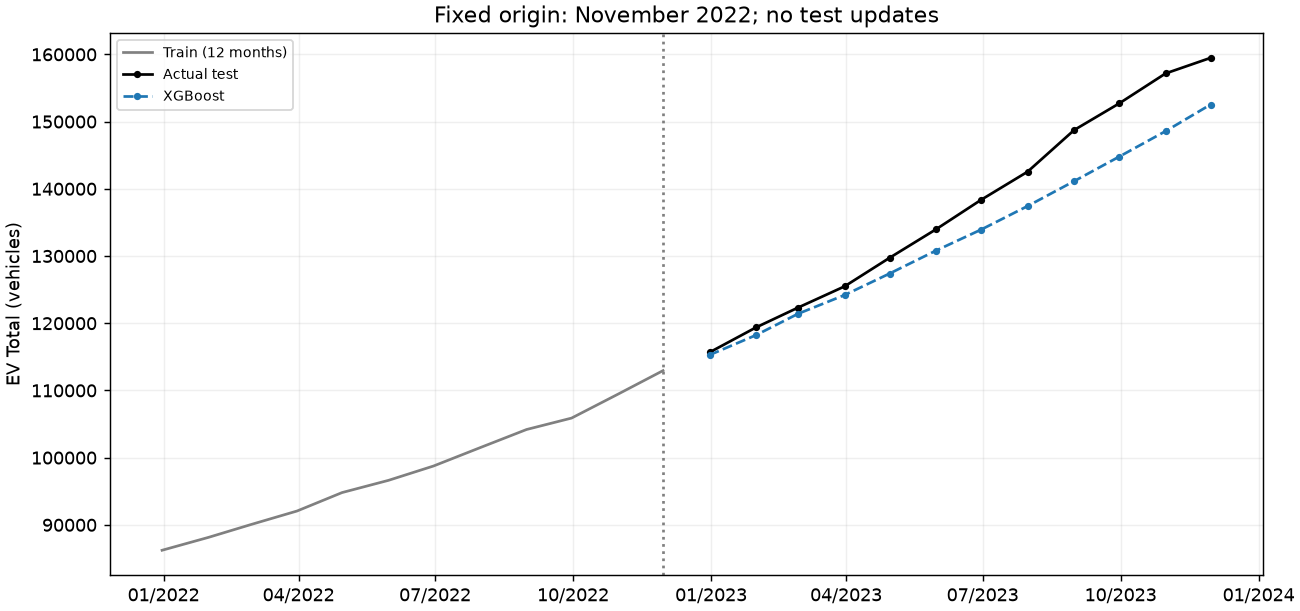

In [9]:
pred, rows = ml.forecast_with_trace(artifact,train,12)
trace = pd.DataFrame(rows)
trace.insert(0,'date',test.date.dt.strftime('%Y-%m-%d').to_numpy())
compare_values('Step 2 lag uses predicted growth',trace.loc[1,'r_lag_1'],trace.loc[0,'r_pred'])
forecast = forecast_frame('xgboost',selected['config_id'],test,pred)
display(trace)
display(forecast[['date','actual','pred']])
series_plot(train,test,{'XGBoost':pred})


## Chấm điểm và đối chiếu dự báo
Không dùng test để chọn lại config. Khoảng dự báo ML chưa được ước lượng, giữ trống.

In [10]:
metric = calculate_metrics(test.ev_total,pred)
display(pd.DataFrame([dict(model='XGBoost',**metric)]))
reference = pd.read_csv(PROJECT_ROOT/'results/forecasting/forecast_xgboost.csv')
compare_values('XGBoost forecast vs published result',pred,reference.pred)
assert forecast[['lower_95','upper_95','interval_level']].isna().all().all()
save_table(forecast,OUT/'forecast_xgboost.csv')
save_table(trace,OUT/'trace_xgboost.csv')
save_table(scores,OUT/'candidate_scores_xgboost.csv')
save_table(cv,OUT/'cv_xgboost.csv')
save_table(validation_forecasts,OUT/'validation_forecasts_xgboost.csv')
save_json({'config':selected,'fit':fitted_info,'test_metrics':metric},OUT/'demo_fit.json')


,model,rmse,mae,smape,bias
0,XGBoost,5064.830985,4154.766382,2.904539,4154.766382


,check,passed,max_absolute_difference
0,XGBoost forecast vs published result,True,2.910383e-11


## Giới hạn diễn giải
Một gốc test 12 tháng không chứng minh ưu thế dài hạn. Các fold CV chồng lấn, không coi là mẫu độc lập. Nếu môi trường/dữ liệu đổi và kết quả lệch, giữ kết quả thật và kiểm tra nguyên nhân; không sửa số cho giống bảng cũ.